# 0. Question of interest, hypothesis and workflow

## Research question

We want to investigate whether the knee abduction-adduction moment (`tKAA`) differs according to:

1. Clinical Treatment group (`Conservative` vs `TKR-planned`)
2. Gender (`Female` vs `Male`)
3. The interaction between Clinical Treatment and Gender

Because there are two categorical independent variables and one continuous dependent variable, a two-factor ANOVA will be used.

## Hypotheses

### Clinical Treatment
- H0: Mean `tKAA` does not differ between Clinical Treatment groups.
- H1: Mean `tKAA` differs between Clinical Treatment groups.

### Gender
- H0: Mean `tKAA` does not differ between genders.
- H1: Mean `tKAA` differs between genders.

### Interaction
- H0: There is no Clinical Treatment × Gender interaction for `tKAA`.
- H1: There is a Clinical Treatment × Gender interaction for `tKAA`.

## Analysis plan

1. Inspect the four Treatment × Gender groups.
2. Calculate descriptive statistics for each group.
3. Visualize the group differences.
4. Compute the two-factor ANOVA.
5. Test:
   - Clinical Treatment main effect
   - Gender main effect
   - Clinical Treatment × Gender interaction
6. Check ANOVA assumptions.
7. Report and interpret the results.

# 1. Import dependencies & load datasets

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import f
from scipy.stats import probplot
from scipy.stats import shapiro
from scipy.stats import levene

In [3]:
df = pd.read_excel("../data/03_TorqueAnalysis_Data.xlsx")
df.rename(columns={"Paciente": "ID"}, inplace=True)
df.columns, df.shape

(Index(['ID', 'Gender', 'Clinical Treatment', 'AgeGroup', 'BMI_Value', 'tGRVE',
        'tAFE', 'tKFE', 'tKAA', 'tKIE', 'tHPFE', 'tHPAA', 'tHPIE'],
       dtype='str'),
 (81, 13))

# 2. Exploratory data analysis

In [4]:
df[["ID", "Gender", "Clinical Treatment", "tKAA"]].info()

<class 'pandas.DataFrame'>
RangeIndex: 81 entries, 0 to 80
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  81 non-null     int64  
 1   Gender              81 non-null     str    
 2   Clinical Treatment  81 non-null     str    
 3   tKAA                81 non-null     float64
dtypes: float64(1), int64(1), str(2)
memory usage: 2.7 KB


In [5]:
group_counts = pd.crosstab(
    df["Clinical Treatment"],
    df["Gender"]
)

group_counts

Gender,Female,Male
Clinical Treatment,,
Conservative,25,21
TKR-planned,24,11


In [6]:
groups = df.groupby(
    ["Clinical Treatment", "Gender"]
)["tKAA"]

group_stats = groups.agg(["count", "mean", "std"])

group_stats

count      mean       std
Clinical Treatment Gender                           
Conservative       Female     25  0.337480  0.103607
                   Male       21  0.372619  0.140493
TKR-planned        Female     24  0.455583  0.126578
                   Male       11  0.410455  0.140450

Descriptively, TKR-planned appears to have higher `tKAA` than Conservative.

Gender does not appear to produce a large overall difference in `tKAA`.

A possible interaction pattern is visible because the gender difference reverses:
- Conservative: Male > Female
- TKR-planned: Female > Male

These observations will be formally tested with the two-factor ANOVA.

# 3. Visualization of group differences

## 3.1 Interaction plot


In [7]:
# Mean tKAA for each Treatment × Gender group
interaction_means = (
    df.groupby(["Clinical Treatment", "Gender"])["tKAA"]
    .mean()
    .unstack()
)

interaction_means

Gender,Female,Male
Clinical Treatment,,
Conservative,0.337480,0.372619
TKR-planned,0.455583,0.410455


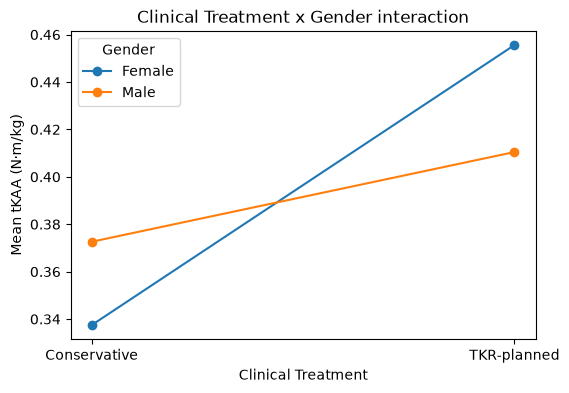

In [ ]:
plt.figure(figsize=(6, 4))

for gender in interaction_means.columns:
    plt.plot(
        interaction_means.index,
        interaction_means[gender],
        marker="o",
        label=gender
    )

plt.xlabel("Clinical Treatment")
plt.ylabel("Mean tKAA (N·m/kg)")
plt.title("Clinical Treatment x Gender interaction")
plt.legend(title="Gender")
plt.show()

## 3.2 Group distributions

In [11]:
df["Group"] = (
    df["Clinical Treatment"]
    + " - "
    + df["Gender"]
)

<Figure size 800x400 with 0 Axes>

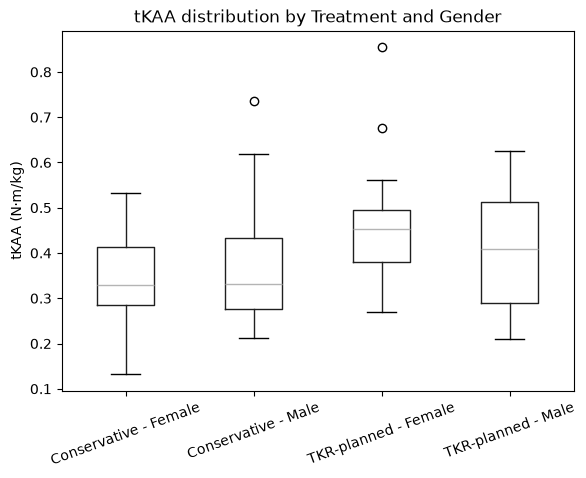

In [14]:
plt.figure(figsize=(8, 4))

df.boxplot(
    column="tKAA",
    by="Group",
    grid=False
)

plt.xlabel("")
plt.ylabel("tKAA (N·m/kg)")
plt.title("tKAA distribution by Treatment and Gender")
plt.suptitle("")
plt.xticks(rotation=20)
plt.show()

# 4. Two-factor ANOVA

## 4.1 Grand mean and group means

First, the overall mean of `tKAA` and the mean value for each Treatment x Gender group are calculated. These quantities summarize the central tendency of the data and will be used in the ANOVA calculations.

In [15]:
grand_mean = df["tKAA"].mean()

grand_mean

np.float64(0.3914938271604938)

In [16]:
group_means = (
    df.groupby(["Clinical Treatment", "Gender"])["tKAA"]
    .mean()
)

group_means

Clinical Treatment  Gender
Conservative        Female    0.337480
                    Male      0.372619
TKR-planned         Female    0.455583
                    Male      0.410455
Name: tKAA, dtype: float64

In [17]:
group_sizes = (
    df.groupby(["Clinical Treatment", "Gender"])["tKAA"]
    .count()
)

group_sizes

Clinical Treatment  Gender
Conservative        Female    25
                    Male      21
TKR-planned         Female    24
                    Male      11
Name: tKAA, dtype: int64

## 4.2 Residual variability

The residual variability represents the variation of individual `tKAA` values around the mean of their own Treatment x Gender group.

For each participant, the residual is calculated as:

$e_{ijk} = Y_{ijk} - \bar{Y}_{ij}$

The squared residuals are then summed to obtain the error sum of squares, $(SS_{\mathrm{Error}})$.

In [18]:
df["group_mean"] = (
    df.groupby(["Clinical Treatment", "Gender"])["tKAA"]
    .transform("mean")
)

df[["tKAA", "group_mean"]].head()

,tKAA,group_mean
0,0.478,0.372619
1,0.150,0.337480
2,0.321,0.337480
3,0.468,0.337480
4,0.329,0.337480


In [19]:
df["residual"] = df["tKAA"] - df["group_mean"]

df[["tKAA", "group_mean", "residual"]].head()

,tKAA,group_mean,residual
0,0.478,0.372619,0.105381
1,0.150,0.337480,-0.187480
2,0.321,0.337480,-0.016480
3,0.468,0.337480,0.130520
4,0.329,0.337480,-0.008480


In [20]:
df["residual_squared"] = df["residual"] ** 2

df[["residual", "residual_squared"]].head()

,residual,residual_squared
0,0.105381,0.011105
1,-0.187480,0.035149
2,-0.016480,0.000272
3,0.130520,0.017035
4,-0.008480,0.000072


In [21]:
SS_error = df["residual_squared"].sum()

SS_error

np.float64(1.2181577529870131)

The residual degrees of freedom are calculated as the total number of observations minus the number of Treatment x Gender groups.

The mean square error is then:

$MSE = \frac{SS_{\mathrm{Error}}}{df_{\mathrm{Error}}}$

This represents the estimated within-group variability and will be used in the following hypothesis tests.

In [22]:
N = len(df)

df_error = N - 4

df_error

77

In [23]:
MSE = SS_error / df_error

MSE

np.float64(0.015820230558272898)

## 4.3 Interaction

The interaction tests whether the difference in mean `tKAA` between Clinical Treatment groups depends on Gender.

For a 2 × 2 design, the interaction can be expressed as a difference of differences:

$C_I = (\bar{Y}_{\mathrm{TKR,F}} - \bar{Y}_{\mathrm{Cons,F}}) - (\bar{Y}_{\mathrm{TKR,M}} - \bar{Y}_{\mathrm{Cons,M}})$


If this contrast is close to zero, the Treatment difference is similar for both genders. A larger non-zero value suggests a possible interaction.

In [24]:
mean_CF = group_means["Conservative", "Female"]
mean_CM = group_means["Conservative", "Male"]

mean_TF = group_means["TKR-planned", "Female"]
mean_TM = group_means["TKR-planned", "Male"]

mean_CF, mean_CM, mean_TF, mean_TM

(np.float64(0.33748),
 np.float64(0.3726190476190476),
 np.float64(0.4555833333333334),
 np.float64(0.4104545454545454))

First, the difference between TKR-planned and Conservative is calculated separately for Female and Male participants. The difference between these two differences gives the interaction contrast.

In [25]:
difference_female = mean_TF - mean_CF
difference_male = mean_TM - mean_CM

interaction_contrast = difference_female - difference_male

difference_female, difference_male, interaction_contrast

(np.float64(0.1181033333333334),
 np.float64(0.03783549783549778),
 np.float64(0.08026783549783562))

The interaction contrast must be compared with the variability expected from the data.

Because the four groups have different sample sizes, the variance of the interaction contrast is calculated using the residual mean square (`MSE`) and the sample size of each group:

$\mathrm{Var}(C_I) = MSE\left( \frac{1}{n_{CF}} + \frac{1}{n_{CM}} + \frac{1}{n_{TF}} + \frac{1}{n_{TM}} \right)$

In [26]:
n_CF = group_sizes["Conservative", "Female"]
n_CM = group_sizes["Conservative", "Male"]

n_TF = group_sizes["TKR-planned", "Female"]
n_TM = group_sizes["TKR-planned", "Male"]

In [27]:
var_interaction = MSE * (
    1 / n_CF
    + 1 / n_CM
    + 1 / n_TF
    + 1 / n_TM
)

var_interaction

np.float64(0.003483532585915805)

The interaction contrast is converted into an F statistic:

$F = \frac{C_I^2}{\mathrm{Var}(C_I)}$

The interaction has one numerator degree of freedom. The p-value is then obtained from the F distribution using the residual degrees of freedom as the denominator degrees of freedom.

In [28]:
F_interaction = interaction_contrast**2 / var_interaction

F_interaction

np.float64(1.8495378632474548)

In [29]:
p_interaction = 1 - f.cdf(
    F_interaction,
    1,
    df_error
)

p_interaction

np.float64(0.1778058375275191)

Since the interaction p-value is greater than 0.05, the null hypothesis of no Clinical Treatment × Gender interaction is not rejected.

Although the descriptive means suggest that the Treatment difference is larger in females than in males, this interaction is not statistically significant.

## 4.4 Clinical Treatment main effect


The Clinical Treatment main effect tests whether mean `tKAA` differs between the Conservative and TKR-planned groups after considering both genders.

Because the Treatment x Gender groups have unequal sample sizes, adjusted Treatment means are calculated by giving equal weight to the Female and Male group means:

$ \bar{Y}_{\mathrm{Cons,adj}} = \frac{\bar{Y}_{CF}+\bar{Y}_{CM}}{2}$

$\bar{Y}_{\mathrm{TKR,adj}} = \frac{\bar{Y}_{TF}+\bar{Y}_{TM}}{2}$

The difference between these adjusted means is then tested using the residual variability estimated by the MSE.

In [30]:
mean_cons_adj = (mean_CF + mean_CM) / 2
mean_tkr_adj = (mean_TF + mean_TM) / 2

mean_cons_adj, mean_tkr_adj

(np.float64(0.3550495238095238), np.float64(0.43301893939393943))

The Treatment contrast is the difference between the adjusted TKR-planned and Conservative means:

$ C_T = \bar{Y}_{\mathrm{TKR,adj}} - \bar{Y}_{\mathrm{Cons,adj}}$

A value of zero would indicate no difference between Treatment groups.

In [31]:
treatment_contrast = mean_tkr_adj - mean_cons_adj

treatment_contrast

np.float64(0.07796941558441561)

The variance of the Treatment contrast depends on the residual variability and on the sample sizes of the four groups.

Because each cell mean contributes with weight \(1/2\), the variance is:

$\mathrm{Var}(C_T) = MSE \left[ \frac{1}{4n_{CF}} + \frac{1}{4n_{CM}} + \frac{1}{4n_{TF}} + \frac{1}{4n_{TM}} \right]$

In [32]:
var_treatment = MSE * (
    1 / (4 * n_CF)
    + 1 / (4 * n_CM)
    + 1 / (4 * n_TF)
    + 1 / (4 * n_TM)
)

var_treatment

np.float64(0.0008708831464789513)

The Treatment contrast is converted into an F statistic:

$ F = \frac{C_T^2}{\mathrm{Var}(C_T)}$

The Treatment main effect has one numerator degree of freedom. The corresponding p-value is obtained from the F distribution.

In [33]:
F_treatment = treatment_contrast**2 / var_treatment

F_treatment

np.float64(6.98053440482126)

In [34]:
p_treatment = 1 - f.cdf(
    F_treatment,
    1,
    df_error
)

p_treatment

np.float64(0.009976453544837893)

Since the Treatment p-value is below 0.05, the null hypothesis of equal mean `tKAA` between Clinical Treatment groups is rejected.

The adjusted mean `tKAA` is significantly higher in the TKR-planned group than in the Conservative group.

## 4.5 Gender main effect

The Gender main effect tests whether mean `tKAA` differs between Female and Male participants after considering both Clinical Treatment groups.

Because the Treatment x Gender groups have unequal sample sizes, adjusted Gender means are calculated by giving equal weight to the Conservative and TKR-planned group means:

$\bar{Y}_{\mathrm{Female,adj}} = \frac{\bar{Y}_{CF}+\bar{Y}_{TF}}{2}$

$\bar{Y}_{\mathrm{Male,adj}} = \frac{\bar{Y}_{CM}+\bar{Y}_{TM}}{2}$

The difference between these adjusted means is then tested using the residual variability estimated by the MSE.

In [35]:
mean_female_adj = (mean_CF + mean_TF) / 2
mean_male_adj = (mean_CM + mean_TM) / 2

mean_female_adj, mean_male_adj

(np.float64(0.3965316666666667), np.float64(0.3915367965367965))

The Gender contrast is the difference between the adjusted Female and Male means:

$C_G = \bar{Y}_{\mathrm{Female,adj}} - \bar{Y}_{\mathrm{Male,adj}}$

A value close to zero would indicate little difference between genders.

In [36]:
gender_contrast = mean_female_adj - mean_male_adj

gender_contrast

np.float64(0.00499487012987021)

The variance of the Gender contrast is calculated using the residual variability and the sample sizes of the four groups.

As each cell mean contributes with weight \(1/2\), the variance is:

$\mathrm{Var}(C_G) = MSE \left[\frac{1}{4n_{CF}} + \frac{1}{4n_{CM}} + \frac{1}{4n_{TF}} + \frac{1}{4n_{TM}} \right]$

In [37]:
var_gender = MSE * (
    1 / (4 * n_CF)
    + 1 / (4 * n_CM)
    + 1 / (4 * n_TF)
    + 1 / (4 * n_TM)
)

var_gender

np.float64(0.0008708831464789513)

The Gender contrast is converted into an F statistic:

$F = \frac{C_G^2}{\mathrm{Var}(C_G)}$

The Gender main effect has one numerator degree of freedom. The corresponding p-value is obtained from the F distribution.

In [38]:
F_gender = gender_contrast**2 / var_gender

F_gender

np.float64(0.028647617898152365)

In [39]:
p_gender = 1 - f.cdf(
    F_gender,
    1,
    df_error
)

p_gender

np.float64(0.8660390892360119)

Since the Gender p-value is greater than 0.05, the null hypothesis of equal mean `tKAA` between Female and Male participants is not rejected.

There is no statistically significant Gender main effect on `tKAA`.

## 4.6 ANOVA table

The results of the three hypothesis tests are summarized in an ANOVA table.

For each effect, the table reports:

- Sum of squares (`SS`): variability associated with that effect.
- Degrees of freedom (`df`).
- Mean square (`MS`): $(SS/df)$.
- F statistic: ratio between the effect variability and the residual variability.
- p-value.

Each main effect and the interaction have one degree of freedom. Therefore, for these effects, \(MS = SS\).

In [40]:
SS_treatment = F_treatment * MSE
SS_gender = F_gender * MSE
SS_interaction = F_interaction * MSE

SS_treatment, SS_gender, SS_interaction

(np.float64(0.11043366370422861),
 np.float64(0.00045321192009407566),
 np.float64(0.029260115422830146))

In [41]:
anova_table = pd.DataFrame({
    "SS": [
        SS_treatment,
        SS_gender,
        SS_interaction,
        SS_error
    ],
    
    "df": [
        1,
        1,
        1,
        df_error
    ],
    
    "MS": [
        SS_treatment,
        SS_gender,
        SS_interaction,
        MSE
    ],
    
    "F": [
        F_treatment,
        F_gender,
        F_interaction,
        np.nan
    ],
    
    "p-value": [
        p_treatment,
        p_gender,
        p_interaction,
        np.nan
    ]
},
index=[
    "Clinical Treatment",
    "Gender",
    "Treatment × Gender",
    "Error"
])

anova_table

,SS,df,MS,F,p-value
Clinical Treatment,0.110434,1,0.110434,6.980534,0.009976
Gender,0.000453,1,0.000453,0.028648,0.866039
Treatment × Gender,0.029260,1,0.029260,1.849538,0.177806
Error,1.218158,77,0.015820,NaN,NaN


The ANOVA indicates a statistically significant main effect of Clinical Treatment (`p < 0.05`).

No statistically significant main effect of Gender was found (`p > 0.05`), and the Clinical Treatment × Gender interaction was also not statistically significant (`p > 0.05`).

# 5. Assumption checks

## 5.1 Independence

ANOVA assumes that the observations are independent, meaning that the value measured for one participant does not determine or influence the value measured for another participant.

In this dataset, each row corresponds to a different participant and each participant contributes only one `tKAA` observation to the analysis. Therefore, the independence assumption is considered reasonable based on the study design.

## 5.2 Normality of residuals

ANOVA assumes that the model residuals are approximately normally distributed.

This assumption is assessed using a Q-Q plot. If the residuals are approximately normal, the points should lie close to the reference line. Large systematic deviations from the line would indicate departures from normality.

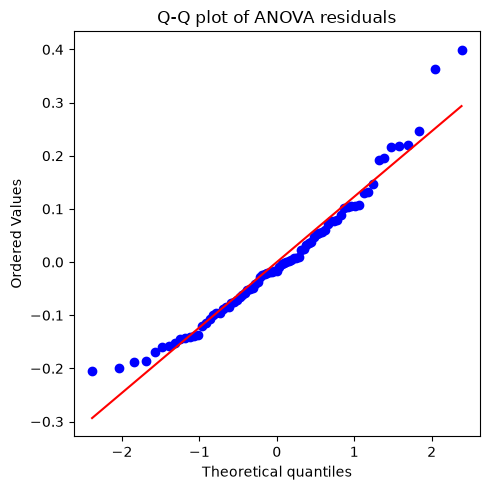

In [43]:
plt.figure(figsize=(5, 5))

probplot(
    df["residual"],
    dist="norm",
    plot=plt
)

plt.title("Q-Q plot of ANOVA residuals")
plt.tight_layout()
plt.show()

In [50]:
shapiro_stat, shapiro_p = shapiro(df["residual"])

shapiro_stat, shapiro_p

(np.float64(0.9587155714946087), np.float64(0.010549497783715745))

The Shapiro-Wilk test indicated a deviation from normality (`p = 0.011`), mainly due to deviations in the tails of the Q-Q plot. Since the residuals were otherwise reasonably aligned with the reference line and the homogeneity of variance assumption was satisfied, the ANOVA was retained.

## 5.3 Homogeneity of variance

ANOVA assumes that the variance of `tKAA` is similar across the four Treatment × Gender groups.

This assumption is assessed by comparing the variability of the groups and using Levene's test. The null hypothesis of Levene's test is that the group variances are equal.

In [47]:
CF = df[
    (df["Clinical Treatment"] == "Conservative") &
    (df["Gender"] == "Female")
]["tKAA"]

CM = df[
    (df["Clinical Treatment"] == "Conservative") &
    (df["Gender"] == "Male")
]["tKAA"]

TF = df[
    (df["Clinical Treatment"] == "TKR-planned") &
    (df["Gender"] == "Female")
]["tKAA"]

TM = df[
    (df["Clinical Treatment"] == "TKR-planned") &
    (df["Gender"] == "Male")
]["tKAA"]

In [48]:
levene_stat, levene_p = levene(
    CF,
    CM,
    TF,
    TM
)

levene_stat, levene_p

(np.float64(0.5009487681307652), np.float64(0.6827399262256))

Levene's test was not statistically significant (`p = 0.683`), so the homogeneity of variance assumption was considered satisfied.